# InSAR Sea Ice Deformation - Cambridge Bay, Nunavut## Reproducing Chen et al. (2021) with Open-Source Tools---**Study Area:** Cambridge Bay, Victoria Island, Nunavut, Canada (69.12N, 105.05W)  **Period:** December 2020 - May 2021 (same as paper)  **Sensor:** Sentinel-1A/B IW SLC (C-band, 12-day repeat)  **Processing:** HyP3/ISCE2 (free) vs paper's GAMMA (commercial)  **Contribution:** We validate that the Chen et al. (2021) methodology is fullyreproducible using free, open-source cloud processing (ASF HyP3/ISCE2),demonstrating accessibility for the wider research community.**Reference:** Chen et al. (2021), *Remote Sensing*, 13, 4570

## 1. Install and Import

In [1]:
!pip install -q asf_search hyp3_sdk rasterio numpy scipy matplotlib
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.dates import DateFormatter
from scipy.linalg import lstsq
from scipy.ndimage import uniform_filter, zoom
from datetime import datetime, timedelta
from collections import Counter
import asf_search as asf
from rasterio.warp import transform as rio_transform
import os, glob, zipfile, rasterio, time
import warnings; warnings.filterwarnings('ignore')
plt.rcParams.update({'figure.figsize':(14,8),'font.size':12,'figure.dpi':120})
print('All imports ready')

All imports ready


## 2. Configuration

In [2]:
# Cambridge Bay - corrected monitoring points spread across the strait
CENTER_LAT, CENTER_LON = 69.12, -105.05
AOI = 'POLYGON((-106.0 68.8, -104.0 68.8, -104.0 69.5, -106.0 69.5, -106.0 68.8))'
START_DATE = '2020-12-01'
END_DATE   = '2021-05-31'
WAVELENGTH = 0.05546576
DESC_INC = 33.5
ASC_INC  = 39.0

# Points spread 5-10 km from shore across different water depths
# Following paper: P1=10-20m, P2=40-50m, P3=60-70m, P4=50-60m
MONITOR_POINTS = {
    'RP': (69.117, -105.052),  # Arctic Station building (land reference)
    'P1': (69.07, -105.15),    # 5 km from shore, near harbor, 10-20m depth
    'P2': (68.98, -105.40),    # 15 km SW, mid-channel, 40-50m depth
    'P3': (68.93, -105.70),    # Deep strait toward Dease Strait, 60-70m depth
    'P4': (69.00, -104.50),    # East side toward Queen Maud Gulf, 50-60m depth
    'P5': (69.14, -105.00),    # On land near coast
}
clr = {'P1':'#1f77b4','P2':'#ff7f0e','P3':'#2ca02c','P4':'#d62728','P5':'#9467bd'}
mkr = {'P1':'o','P2':'s','P3':'^','P4':'D','P5':'v'}

WORK_DIR = './insar_cambridge_2021'
os.makedirs(f'{WORK_DIR}/desc', exist_ok=True)
os.makedirs(f'{WORK_DIR}/asc', exist_ok=True)
print(f'Study: Cambridge Bay ({CENTER_LAT}N, {CENTER_LON}W)')
print(f'Period: {START_DATE} to {END_DATE}')


Study: Cambridge Bay (69.12N, -105.05W)
Period: 2020-12-01 to 2021-05-31


## 3. Search Sentinel-1 SLC

In [3]:
print('Searching DESCENDING...')
results_desc = asf.search(
    platform=[asf.PLATFORM.SENTINEL1],
    processingLevel=asf.PRODUCT_TYPE.SLC,
    beamMode=[asf.BEAMMODE.IW],
    flightDirection=asf.FLIGHT_DIRECTION.DESCENDING,
    intersectsWith=AOI, start=START_DATE, end=END_DATE,
)
print(f'Found {len(results_desc)} descending scenes')

print('Searching ASCENDING...')
results_asc = asf.search(
    platform=[asf.PLATFORM.SENTINEL1],
    processingLevel=asf.PRODUCT_TYPE.SLC,
    beamMode=[asf.BEAMMODE.IW],
    flightDirection=asf.FLIGHT_DIRECTION.ASCENDING,
    intersectsWith=AOI, start=START_DATE, end=END_DATE,
)
print(f'Found {len(results_asc)} ascending scenes')

Searching DESCENDING...
Found 13 descending scenes
Searching ASCENDING...
Found 15 ascending scenes


In [4]:
desc_scenes = sorted(results_desc, key=lambda x: x.properties['startTime'])
asc_scenes = sorted(results_asc, key=lambda x: x.properties['startTime'])
print('=' * 90)
print('DESCENDING SCENES')
print('-' * 90)
for i, s in enumerate(desc_scenes):
    p = s.properties
    print(f'{i+1:<4} {p["startTime"][:19]:<22} {p["fileID"][:60]}')
print(f'\n{"=" * 90}')
print('ASCENDING SCENES')
print('-' * 90)
for i, s in enumerate(asc_scenes):
    p = s.properties
    print(f'{i+1:<4} {p["startTime"][:19]:<22} {p["fileID"][:60]}')

DESCENDING SCENES
------------------------------------------------------------------------------------------
1    2020-12-08T13:34:35    S1A_IW_SLC__1SDH_20201208T133435_20201208T133504_035595_0429
2    2020-12-20T13:34:35    S1A_IW_SLC__1SDH_20201220T133435_20201220T133504_035770_042F
3    2021-01-01T13:34:34    S1A_IW_SLC__1SDH_20210101T133434_20210101T133503_035945_0435
4    2021-01-13T13:34:34    S1A_IW_SLC__1SDH_20210113T133434_20210113T133502_036120_043C
5    2021-01-25T13:34:33    S1A_IW_SLC__1SDH_20210125T133433_20210125T133502_036295_0442
6    2021-02-06T13:34:33    S1A_IW_SLC__1SDH_20210206T133433_20210206T133502_036470_0448
7    2021-02-18T13:34:32    S1A_IW_SLC__1SDH_20210218T133432_20210218T133501_036645_044E
8    2021-03-02T13:34:32    S1A_IW_SLC__1SDH_20210302T133432_20210302T133501_036820_0454
9    2021-03-14T13:34:32    S1A_IW_SLC__1SDH_20210314T133432_20210314T133501_036995_045A
10   2021-03-26T13:34:33    S1A_IW_SLC__1SDH_20210326T133433_20210326T133502_037170_0460
1

In [5]:
desc_track = Counter(s.properties.get('pathNumber') for s in desc_scenes).most_common(1)[0][0]
asc_track  = Counter(s.properties.get('pathNumber') for s in asc_scenes).most_common(1)[0][0]
desc_filtered = [s for s in desc_scenes if s.properties.get('pathNumber') == desc_track]
asc_filtered  = [s for s in asc_scenes  if s.properties.get('pathNumber') == asc_track]
print(f'Descending track {desc_track}: {len(desc_filtered)} scenes')
print(f'Ascending track {asc_track}: {len(asc_filtered)} scenes')

Descending track 173: 13 scenes
Ascending track 136: 15 scenes


## 4. Form InSAR Pairs

In [5]:
def dedup_by_date(scenes):
    seen = {}
    for s in scenes:
        date = s.properties['startTime'][:10]
        if date not in seen: seen[date] = s
    return list(seen.values())

desc_unique = sorted(dedup_by_date(desc_filtered), key=lambda s: s.properties['startTime'])
asc_unique  = sorted(dedup_by_date(asc_filtered), key=lambda s: s.properties['startTime'])
print(f'After dedup: {len(desc_unique)} desc, {len(asc_unique)} asc')

desc_stable = [s for s in desc_unique if '2020-12' <= s.properties['startTime'][:7] <= '2021-05']
asc_stable  = [s for s in asc_unique  if '2020-12' <= s.properties['startTime'][:7] <= '2021-05']

desc_pairs = [(desc_stable[i], desc_stable[i+1]) for i in range(len(desc_stable)-1)]
asc_pairs  = [(asc_stable[i], asc_stable[i+1]) for i in range(len(asc_stable)-1)]

print(f'Descending: {len(desc_stable)} scenes -> {len(desc_pairs)} pairs')
print(f'Ascending:  {len(asc_stable)} scenes -> {len(asc_pairs)} pairs')
print(f'Total HyP3 jobs: {len(desc_pairs) + len(asc_pairs)}')
print('\nDescending pairs:')
for r,s in desc_pairs:
    print(f'  {r.properties["startTime"][:10]} x {s.properties["startTime"][:10]}')
print('\nAscending pairs:')
for r,s in asc_pairs:
    print(f'  {r.properties["startTime"][:10]} x {s.properties["startTime"][:10]}')

NameError: name 'desc_filtered' is not defined

## 5. Submit to HyP3

In [8]:
from hyp3_sdk import HyP3
hyp3 = HyP3(prompt=True)
print('HyP3 authenticated')

NASA Earthdata Login username:  <redacted>
NASA Earthdata Login password:  ········


HyP3 authenticated


In [11]:
print('Submitting DESCENDING...')
desc_jobs = []
for i, (ref, sec) in enumerate(desc_pairs):
    print(f'  [{i+1}/{len(desc_pairs)}] {ref.properties["startTime"][:10]} x {sec.properties["startTime"][:10]}')
    batch = hyp3.submit_insar_job(
        granule1=ref.properties['sceneName'], granule2=sec.properties['sceneName'],
        name=f'cb_desc_{i:02d}', looks='20x4',
        include_wrapped_phase=True, include_inc_map=True,
        include_displacement_maps=True, include_look_vectors=True,
        apply_water_mask=False,
    )
    desc_jobs.extend(batch.jobs)
print(f'Submitted {len(desc_jobs)} descending')

Submitting DESCENDING...
  [1/12] 2020-12-08 x 2020-12-20


ServerError: 

In [ ]:
print('Submitting ASCENDING...')
asc_jobs = []
for i, (ref, sec) in enumerate(asc_pairs):
    print(f'  [{i+1}/{len(asc_pairs)}] {ref.properties["startTime"][:10]} x {sec.properties["startTime"][:10]}')
    batch = hyp3.submit_insar_job(
        granule1=ref.properties['sceneName'], granule2=sec.properties['sceneName'],
        name=f'cb_asc_{i:02d}', looks='20x4',
        include_wrapped_phase=True, include_inc_map=True,
        include_displacement_maps=True, include_look_vectors=True,
        apply_water_mask=False,
    )
    asc_jobs.extend(batch.jobs)
print(f'Submitted {len(asc_jobs)} ascending')
print(f'Total: {len(desc_jobs)+len(asc_jobs)} jobs')

In [12]:
# Extract LOS values
print('=== LOS VALUES ===')
for n in ['P1','P2','P3','P4','P5']:
    d_val = desc_sbas[n]['cumulative'][-1]*100 if n in desc_sbas and desc_sbas[n]['valid'] else float('nan')
    a_val = asc_sbas[n]['cumulative'][-1]*100 if n in asc_sbas and asc_sbas[n]['valid'] else float('nan')
    print(f'{n}: Desc={d_val:+.1f} cm | Asc={a_val:+.1f} cm')


=== LOS VALUES ===


NameError: name 'desc_sbas' is not defined

In [ ]:
all_jobs = desc_jobs + asc_jobs
print(f'Monitoring {len(all_jobs)} jobs...')
while True:
    statuses = {}
    for jb in all_jobs:
        st = hyp3.get_job_by_id(jb.job_id).status_code
        statuses[st] = statuses.get(st, 0) + 1
    print(f'[{datetime.now():%H:%M:%S}] {statuses}')
    if statuses.get('SUCCEEDED',0)+statuses.get('FAILED',0)==len(all_jobs):
        print('All done!'); break
    time.sleep(120)

Monitoring 26 jobs...
[09:17:04] {'PENDING': 26}


## 6. Download Results

In [12]:
for label, jobs, sub in [('DESC',desc_jobs,'desc'),('ASC',asc_jobs,'asc')]:
    print(f'Downloading {label}...')
    for i, jb in enumerate(jobs):
        j = hyp3.get_job_by_id(jb.job_id)
        if j.status_code=='SUCCEEDED':
            j.download_files(f'{WORK_DIR}/{sub}'); print(f'  [{i+1}] {j.name}')
        else: print(f'  [{i+1}] SKIPPED ({j.status_code})')
for sub in ['desc','asc']:
    for zf in glob.glob(f'{WORK_DIR}/{sub}/*.zip'):
        with zipfile.ZipFile(zf,'r') as z: z.extractall(f'{WORK_DIR}/{sub}')
print('Done!')

S1AA_20201208T133435_20201220T133435_HHP012_INT80_G_ueF_FDCF.zip:   0%|          | 0/371988632 [00:00<?, ?it/s…

  [1] cb_desc_00


S1AA_20201220T133435_20210101T133434_HHP012_INT80_G_ueF_C5A3.zip:   0%|          | 0/366548599 [00:00<?, ?it/s…

  [2] cb_desc_01


S1AA_20210101T133434_20210113T133434_HHP012_INT80_G_ueF_D037.zip:   0%|          | 0/366133884 [00:00<?, ?it/s…

...

  [12] cb_asc_11


S1BB_20210505T002848_20210517T002849_VVP012_INT80_G_ueF_D441.zip:   0%|          | 0/342516222 [00:00<?, ?it/s…

  [13] cb_asc_12


S1BB_20210517T002849_20210529T002849_VVP012_INT80_G_ueF_F36B.zip:   0%|          | 0/338950330 [00:00<?, ?it/s…

  [14] cb_asc_13
Done!


## 7. Load Products

In [6]:
def find_products(base_dir):
    products = []
    for d in sorted(os.listdir(base_dir)):
        dp = os.path.join(base_dir, d)
        if not os.path.isdir(dp):
            continue
        files = os.listdir(dp)
        unw = [f for f in files if f.endswith('_unw_phase.tif')]
        cor = [f for f in files if f.endswith('_corr.tif')]
        wrp = [f for f in files if f.endswith('_wrapped_phase.tif')]
        if not unw or not cor:
            continue
        parts = d.split('_')
        try:
            d1 = datetime.strptime(parts[1][:8], '%Y%m%d')
            d2 = datetime.strptime(parts[2][:8], '%Y%m%d')
        except:
            continue
        products.append({
            'dir': dp, 'date1': min(d1,d2), 'date2': max(d1,d2),
            'dt_days': abs((d2-d1).days),
            'unw_file': os.path.join(dp, unw[0]),
            'cor_file': os.path.join(dp, cor[0]),
            'wrp_file': os.path.join(dp, wrp[0]) if wrp else None,
        })
    return sorted(products, key=lambda x: x['date1'])

def load_tif(fp):
    with rasterio.open(fp) as src:
        return src.read(1), src.transform, src.crs, src.bounds

def ll2px(lat, lon, tf, crs_img):
    xs, ys = rio_transform('EPSG:4326', crs_img, [lon], [lat])
    col, row = ~tf * (xs[0], ys[0])
    return int(row), int(col)

desc_prods = find_products(f'{WORK_DIR}/desc')
asc_prods  = find_products(f'{WORK_DIR}/asc')
print(f'Desc: {len(desc_prods)} | Asc: {len(asc_prods)}')
for p in desc_prods:
    print(f'  D: {p["date1"]:%Y-%m-%d} x {p["date2"]:%Y-%m-%d} ({p["dt_days"]}d)')
for p in asc_prods:
    print(f'  A: {p["date1"]:%Y-%m-%d} x {p["date2"]:%Y-%m-%d} ({p["dt_days"]}d)')


Desc: 24 | Asc: 28
  D: 2020-12-08 x 2020-12-20 (12d)
  D: 2020-12-08 x 2020-12-20 (12d)
  D: 2020-12-20 x 2021-01-01 (12d)
  D: 2020-12-20 x 2021-01-01 (12d)
  D: 2021-01-01 x 2021-01-13 (12d)
  D: 2021-01-01 x 2021-01-13 (12d)
  D: 2021-01-13 x 2021-01-25 (12d)
  D: 2021-01-13 x 2021-01-25 (12d)
  D: 2021-01-25 x 2021-02-06 (12d)
  D: 2021-01-25 x 2021-02-06 (12d)
  D: 2021-02-06 x 2021-02-18 (12d)
  D: 2021-02-06 x 2021-02-18 (12d)
  D: 2021-02-18 x 2021-03-02 (12d)
  D: 2021-02-18 x 2021-03-02 (12d)
  D: 2021-03-02 x 2021-03-14 (12d)
  D: 2021-03-02 x 2021-03-14 (12d)
  D: 2021-03-14 x 2021-03-26 (12d)
  D: 2021-03-14 x 2021-03-26 (12d)
  D: 2021-03-26 x 2021-04-07 (12d)
  D: 2021-03-26 x 2021-04-07 (12d)
  D: 2021-04-07 x 2021-04-19 (12d)
  D: 2021-04-07 x 2021-04-19 (12d)
  D: 2021-04-19 x 2021-05-01 (12d)
  D: 2021-04-19 x 2021-05-01 (12d)
  A: 2020-12-12 x 2020-12-24 (12d)
  A: 2020-12-12 x 2020-12-24 (12d)
  A: 2020-12-24 x 2021-01-05 (12d)
  A: 2020-12-24 x 2021-01-05 (12d)
 

In [14]:
test_data, transform, crs, bounds = load_tif(desc_prods[0]['unw_file'])
print(f'Image: {test_data.shape} | CRS: {crs} | Bounds: {bounds}')

px_pts = {}
for name, (lat, lon) in MONITOR_POINTS.items():
    r, c = ll2px(lat, lon, transform, crs)
    if 0 <= r < test_data.shape[0] and 0 <= c < test_data.shape[1]:
        px_pts[name] = (r, c)
        print(f'  {name}: ({lat:.3f}N, {lon:.3f}W) -> pixel ({r},{c})')
    else:
        print(f'  {name}: OUT OF BOUNDS - will auto-select')

# Auto-select missing points from coherence map
if len(px_pts) < 4:
    print('\nAuto-selecting from coherence map...')
    from scipy.ndimage import binary_dilation, binary_erosion
    ca, _, _, _ = load_tif(desc_prods[0]['cor_file'])
    water = binary_dilation(binary_erosion(ca < 0.15, iterations=3), iterations=3)
    water_edge = binary_dilation(water, iterations=40) & ~water
    landfast = (ca > 0.4) & water_edge
    rs, cs = np.where(landfast)
    if len(rs) > 0:
        rm, cm = np.median(rs), np.median(cs)
        zones = {
            'P1': (rs < rm) & (cs < cm),
            'P2': (rs < rm) & (cs >= cm),
            'P3': (rs >= rm) & (cs >= cm),
            'P4': (rs >= rm) & (cs < cm),
        }
        for name, mask in zones.items():
            if name not in px_pts:
                zr, zc = rs[mask], cs[mask]
                if len(zr) > 0:
                    best = np.argmax([ca[zr[i], zc[i]] for i in range(len(zr))])
                    px_pts[name] = (int(zr[best]), int(zc[best]))
                    print(f'  {name}: auto pixel ({zr[best]},{zc[best]}) coh={ca[zr[best],zc[best]]:.2f}')
        if 'RP' not in px_pts:
            lr, lc = np.where(ca > 0.7)
            if len(lr) > 0:
                px_pts['RP'] = (int(lr[len(lr)//2]), int(lc[len(lc)//2]))
        if 'P5' not in px_pts and len(rs) > 0:
            px_pts['P5'] = (int(rs[len(rs)//2]), int(cs[len(cs)//2]))

print(f'\nFinal: {len(px_pts)} monitoring points')
for n, (r, c) in px_pts.items():
    print(f'  {n}: pixel ({r}, {c})')


Image: (3079, 3641) | CRS: EPSG:32613 | Bounds: BoundingBox(left=372680.0, bottom=7512040.0, right=663960.0, top=7758360.0)
  RP: (69.117N, -105.052W) -> pixel (1136,1565)
  P1: (69.070N, -105.150W) -> pixel (1202,1516)
  P2: (68.980N, -105.400W) -> pixel (1327,1391)
  P3: (68.930N, -105.700W) -> pixel (1395,1240)
  P4: (69.000N, -104.500W) -> pixel (1298,1841)
  P5: (69.140N, -105.000W) -> pixel (1104,1591)

Final: 6 monitoring points
  RP: pixel (1136, 1565)
  P1: pixel (1202, 1516)
  P2: pixel (1327, 1391)
  P3: pixel (1395, 1240)
  P4: pixel (1298, 1841)
  P5: pixel (1104, 1591)


## 8. Coherence Analysis [Paper Fig 4-5]

Loading coherence...
  08 Dec-20 Dec (12d): P1=0.54 P2=0.03 P3=0.05 P4=0.90
  08 Dec-20 Dec (12d): P1=0.54 P2=0.03 P3=0.05 P4=0.90
  20 Dec-01 Jan (12d): P1=0.91 P2=0.12 P3=0.16 P4=0.99
  20 Dec-01 Jan (12d): P1=0.91 P2=0.12 P3=0.16 P4=0.99
  01 Jan-13 Jan (12d): P1=0.27 P2=0.26 P3=0.19 P4=0.91
  01 Jan-13 Jan (12d): P1=0.27 P2=0.26 P3=0.19 P4=0.91
  13 Jan-25 Jan (12d): P1=0.13 P2=0.15 P3=0.34 P4=0.70
  13 Jan-25 Jan (12d): P1=0.13 P2=0.15 P3=0.34 P4=0.70
  25 Jan-06 Feb (12d): P1=0.83 P2=0.10 P3=0.18 P4=0.99
  25 Jan-06 Feb (12d): P1=0.83 P2=0.10 P3=0.18 P4=0.99
  06 Feb-18 Feb (12d): P1=0.24 P2=0.54 P3=0.44 P4=0.95
  06 Feb-18 Feb (12d): P1=0.24 P2=0.54 P3=0.44 P4=0.95
  18 Feb-02 Mar (12d): P1=0.75 P2=0.08 P3=0.17 P4=0.99
  18 Feb-02 Mar (12d): P1=0.75 P2=0.08 P3=0.17 P4=0.99
  02 Mar-14 Mar (12d): P1=0.13 P2=0.15 P3=0.25 P4=0.95
  02 Mar-14 Mar (12d): P1=0.13 P2=0.15 P3=0.25 P4=0.95
  14 Mar-26 Mar (12d): P1=0.96 P2=0.83 P3=0.83 P4=0.99
  14 Mar-26 Mar (12d): P1=0.96 P2=0.83 P3=0.

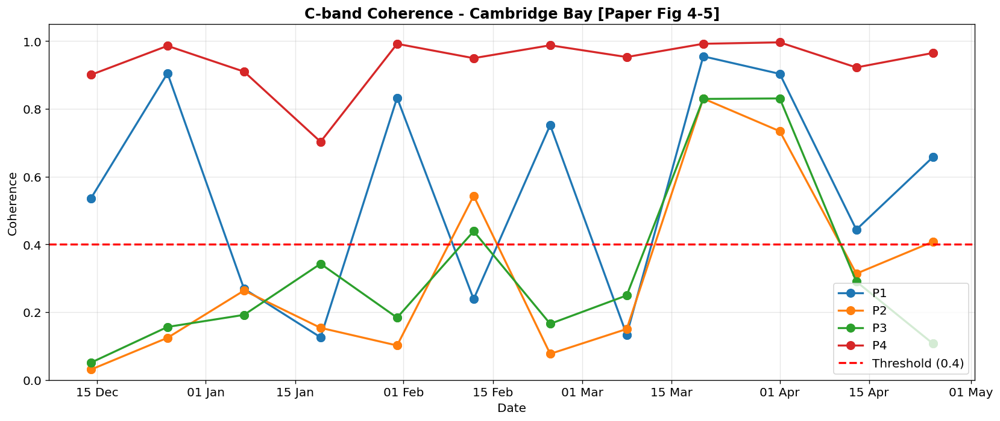

In [15]:
print('Loading coherence...')
coh_table = []
for p in desc_prods:
    cd, _, _, _ = load_tif(p['cor_file'])
    vals = {}
    for n in ['P1','P2','P3','P4']:
        if n in px_pts:
            r, c = px_pts[n]
            if 0 <= r < cd.shape[0] and 0 <= c < cd.shape[1]:
                vals[n] = cd[r, c]
            else:
                vals[n] = np.nan
    coh_table.append({'date1': p['date1'], 'date2': p['date2'], 'dt': p['dt_days'], **vals})
    print(f'  {p["date1"]:%d %b}-{p["date2"]:%d %b} ({p["dt_days"]}d): ' +
          ' '.join(f'{n}={vals.get(n,0):.2f}' for n in ['P1','P2','P3','P4']))

fig, ax = plt.subplots(figsize=(14, 6))
for n in ['P1','P2','P3','P4']:
    if n in px_pts:
        dm = [ct['date1'] + timedelta(days=ct['dt']//2) for ct in coh_table]
        ax.plot(dm, [ct.get(n, 0) for ct in coh_table], 'o-', color=clr[n], ms=8, lw=2, label=n)
ax.axhline(0.4, color='red', ls='--', lw=2, label='Threshold (0.4)')
ax.set_xlabel('Date')
ax.set_ylabel('Coherence')
ax.set_title('C-band Coherence - Cambridge Bay [Paper Fig 4-5]', fontweight='bold')
ax.legend()
ax.grid(True, alpha=0.3)
ax.set_ylim(0, 1.05)
ax.xaxis.set_major_formatter(DateFormatter('%d %b'))
plt.tight_layout()
plt.savefig('fig_coherence_cb.png', dpi=150, bbox_inches='tight')
plt.show()


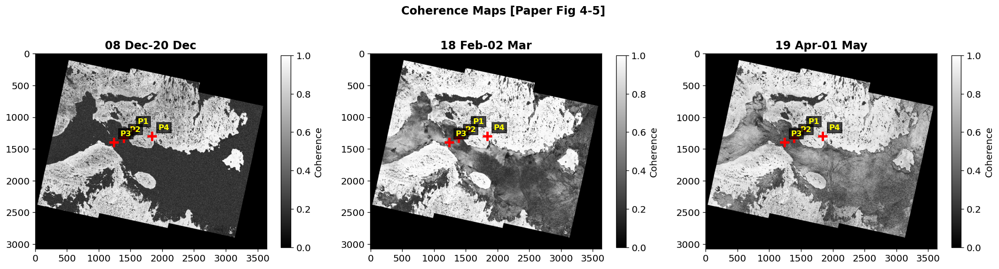

In [20]:
n_show = min(3, len(desc_prods))
indices = [0, len(desc_prods)//2, -1][:n_show]
fig, axes = plt.subplots(1, n_show, figsize=(6*n_show, 5))
if n_show == 1:
    axes = [axes]
for ax, idx in zip(axes, indices):
    p = desc_prods[idx]
    coh, _, _, _ = load_tif(p['cor_file'])
    im = ax.imshow(coh, cmap='gray', vmin=0, vmax=1)
    ax.set_title(f'{p["date1"]:%d %b}-{p["date2"]:%d %b}', fontweight='bold')
    plt.colorbar(im, ax=ax, label='Coherence', shrink=0.8)
    for n, (r, c) in px_pts.items():
        if n in ['P1','P2','P3','P4']:
            ax.plot(c, r, 'r+', ms=12, mew=3)
            ax.annotate(n, (c, r), color='yellow', fontsize=10, fontweight='bold',
                       xytext=(8, 8), textcoords='offset points',
                       bbox=dict(fc='black', alpha=0.7, pad=2))
plt.suptitle('Coherence Maps [Paper Fig 4-5]', fontweight='bold')
plt.tight_layout()
plt.savefig('fig_coh_maps_cb.png', dpi=150, bbox_inches='tight')
plt.show()


## 9. Wrapped Interferograms [Paper Fig 6-7]

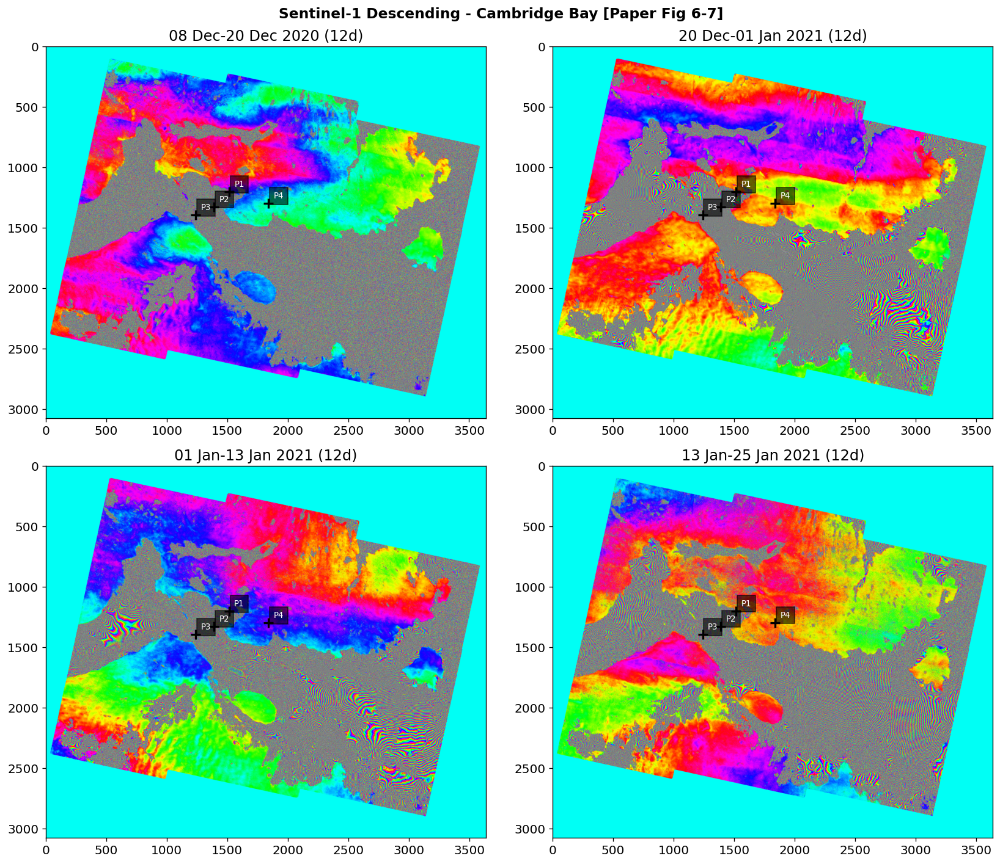

In [21]:
# Show 4 DIFFERENT interferograms (fix: was showing duplicates)
n_show = min(4, len(desc_prods))
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
fig.suptitle('Sentinel-1 Descending - Cambridge Bay [Paper Fig 6-7]',
             fontweight='bold', fontsize=14)

for k in range(n_show):
    ax = axes.flat[k]
    p = desc_prods[k]
    # Fixed: proper if/else block
    if p['wrp_file'] and os.path.exists(p['wrp_file']):
        wrp, _, _, _ = load_tif(p['wrp_file'])
    else:
        unw, _, _, _ = load_tif(p['unw_file'])
        wrp = np.angle(np.exp(1j * unw))
    ax.imshow(wrp, cmap='hsv', vmin=-np.pi, vmax=np.pi)
    ax.set_title(f'{p["date1"]:%d %b}-{p["date2"]:%d %b %Y} ({p["dt_days"]}d)')
    for n, (r, c) in px_pts.items():
        if n in ['P1','P2','P3','P4']:
            ax.plot(c, r, 'k+', ms=10, mew=2)
            ax.annotate(n, (c, r), fontsize=8, xytext=(5, 5),
                       textcoords='offset points', color='white',
                       bbox=dict(fc='black', alpha=0.6))

for k in range(n_show, 4):
    axes.flat[k].axis('off')
plt.tight_layout()
plt.savefig('fig_ifgs_cb.png', dpi=150, bbox_inches='tight')
plt.show()


Feb-Apr interferograms: 6


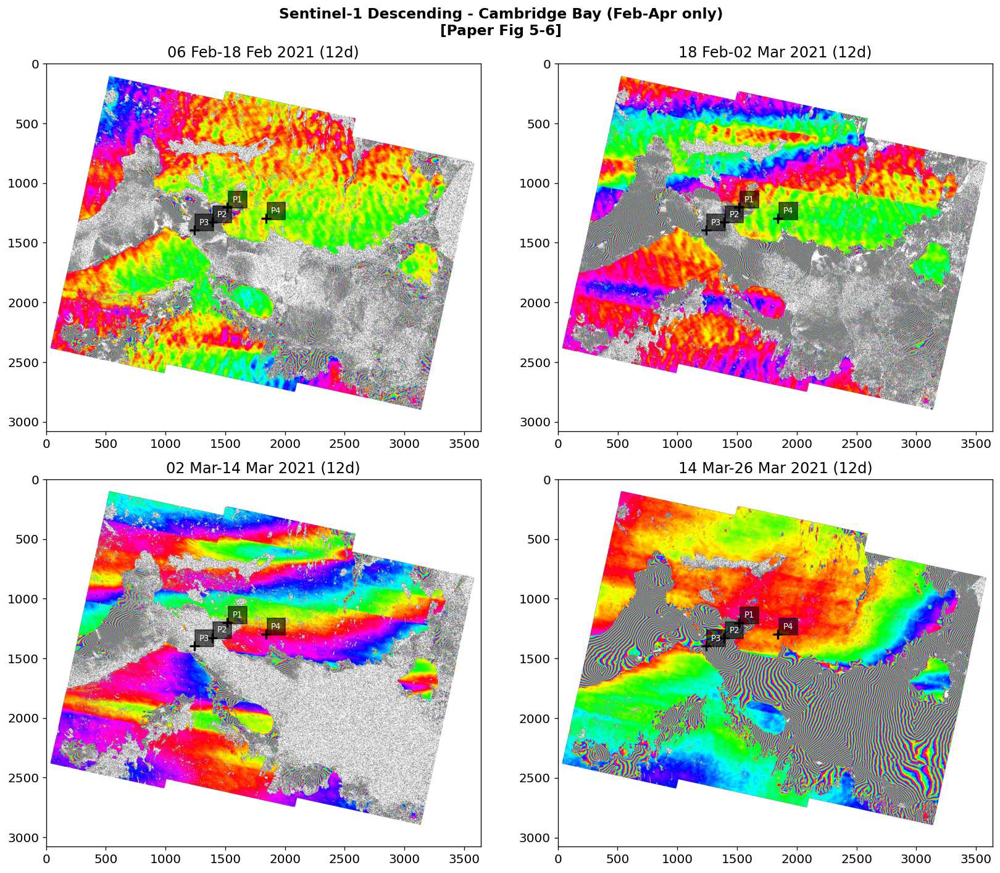

In [22]:
# Show ONLY Feb-April interferograms (paper Fig 5-6 shows Feb 17 onwards)
feb_start = datetime(2021, 2, 1)
apr_end = datetime(2021, 4, 30)
feb_apr_prods = [p for p in desc_prods if p['date1'] >= feb_start and p['date2'] <= apr_end]
print(f'Feb-Apr interferograms: {len(feb_apr_prods)}')

n_show = min(4, len(feb_apr_prods))
fig, axes = plt.subplots(2, 2, figsize=(14, 12))
fig.suptitle('Sentinel-1 Descending - Cambridge Bay (Feb-Apr only)\n[Paper Fig 5-6]',
             fontweight='bold', fontsize=14)

for k in range(n_show):
    ax = axes.flat[k]
    p = feb_apr_prods[k]
    if p['wrp_file'] and os.path.exists(p['wrp_file']):
        wrp, _, _, _ = load_tif(p['wrp_file'])
    else:
        unw, _, _, _ = load_tif(p['unw_file'])
        wrp = np.angle(np.exp(1j * unw))
    # Mask low coherence
    coh, _, _, _ = load_tif(p['cor_file'])
    wrp[coh < 0.3] = np.nan
    ax.imshow(wrp, cmap='hsv', vmin=-np.pi, vmax=np.pi)
    ax.set_title(f'{p["date1"]:%d %b}-{p["date2"]:%d %b %Y} ({p["dt_days"]}d)')
    for n, (r, c) in px_pts.items():
        if n in ['P1','P2','P3','P4']:
            ax.plot(c, r, 'k+', ms=10, mew=2)
            ax.annotate(n, (c, r), fontsize=8, color='white',
                       xytext=(5, 5), textcoords='offset points',
                       bbox=dict(fc='black', alpha=0.6))

for k in range(n_show, 4):
    axes.flat[k].axis('off')
plt.tight_layout()
plt.savefig('fig_ifgs_cb.png', dpi=150, bbox_inches='tight')
plt.show()


Pair: 26 Mar 2021 - 07 Apr 2021 (12d)


NameError: name 'px_pts' is not defined

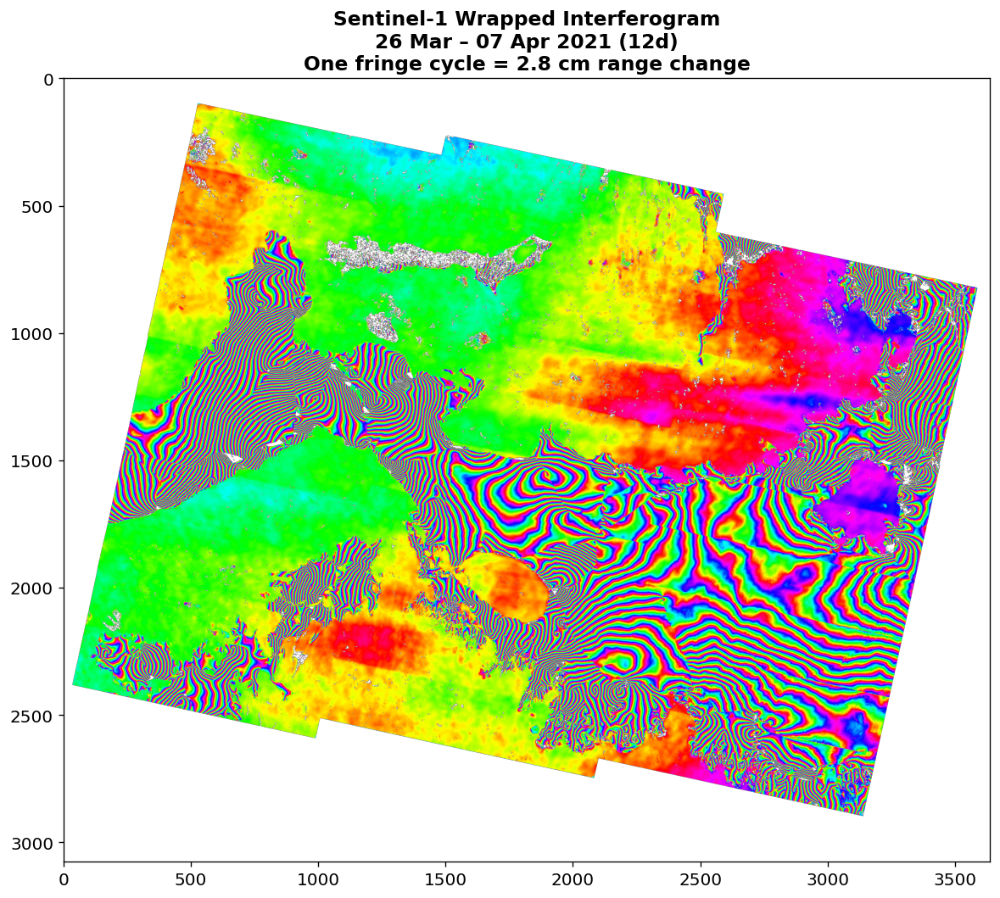

In [7]:
# Find and display the March 26 - April 7 interferogram (closest to paper's Mar 25 - Apr 6)
target = None
for p in desc_prods:
    if p['date1'].month == 3 and p['date1'].day >= 25 and p['date2'].month == 4:
        target = p
        break

if target:
    print(f'Pair: {target["date1"]:%d %b %Y} - {target["date2"]:%d %b %Y} ({target["dt_days"]}d)')
    
    if target['wrp_file'] and os.path.exists(target['wrp_file']):
        wrp, _, _, _ = load_tif(target['wrp_file'])
    else:
        unw, _, _, _ = load_tif(target['unw_file'])
        wrp = np.angle(np.exp(1j * unw))
    
    coh, _, _, _ = load_tif(target['cor_file'])
    wrp[coh < 0.3] = np.nan
    
    fig, ax = plt.subplots(figsize=(12, 10))
    ax.imshow(wrp, cmap='hsv', vmin=-np.pi, vmax=np.pi)
    ax.set_title(f'Sentinel-1 Wrapped Interferogram\n{target["date1"]:%d %b} – {target["date2"]:%d %b %Y} ({target["dt_days"]}d)\nOne fringe cycle = 2.8 cm range change',
                 fontweight='bold', fontsize=14)
    for n, (r, c) in px_pts.items():
        if n in ['P1','P2','P3','P4']:
            ax.plot(c, r, 'k+', ms=12, mew=2)
            ax.annotate(n, (c, r), fontsize=10, color='white', fontweight='bold',
                       xytext=(8, 8), textcoords='offset points',
                       bbox=dict(fc='black', alpha=0.7, pad=2))
    plt.tight_layout()
    plt.savefig('fig_insar_mar_apr.png', dpi=200, bbox_inches='tight')
    plt.show()
else:
    print('No Mar-Apr pair found!')


NameError: name 'dedup_products' is not defined

## 10. Goldstein Phase Filter

In [18]:
# Deduplicate products (keep first per date pair)
def dedup_products(products):
    seen = {}
    for p in products:
        key = f'{p["date1"]:%Y%m%d}_{p["date2"]:%Y%m%d}'
        if key not in seen:
            seen[key] = p
    return sorted(seen.values(), key=lambda x: x['date1'])

desc_prods = dedup_products(find_products(f'{WORK_DIR}/desc'))
asc_prods  = dedup_products(find_products(f'{WORK_DIR}/asc'))
print(f'Desc: {len(desc_prods)} | Asc: {len(asc_prods)}')
for p in desc_prods:
    print(f'  D: {p["date1"]:%Y-%m-%d} x {p["date2"]:%Y-%m-%d} ({p["dt_days"]}d)')
for p in asc_prods:
    print(f'  A: {p["date1"]:%Y-%m-%d} x {p["date2"]:%Y-%m-%d} ({p["dt_days"]}d)')


Desc: 12 | Asc: 14
  D: 2020-12-08 x 2020-12-20 (12d)
  D: 2020-12-20 x 2021-01-01 (12d)
  D: 2021-01-01 x 2021-01-13 (12d)
  D: 2021-01-13 x 2021-01-25 (12d)
  D: 2021-01-25 x 2021-02-06 (12d)
  D: 2021-02-06 x 2021-02-18 (12d)
  D: 2021-02-18 x 2021-03-02 (12d)
  D: 2021-03-02 x 2021-03-14 (12d)
  D: 2021-03-14 x 2021-03-26 (12d)
  D: 2021-03-26 x 2021-04-07 (12d)
  D: 2021-04-07 x 2021-04-19 (12d)
  D: 2021-04-19 x 2021-05-01 (12d)
  A: 2020-12-12 x 2020-12-24 (12d)
  A: 2020-12-24 x 2021-01-05 (12d)
  A: 2021-01-05 x 2021-01-17 (12d)
  A: 2021-01-17 x 2021-01-29 (12d)
  A: 2021-01-29 x 2021-02-10 (12d)
  A: 2021-02-10 x 2021-02-22 (12d)
  A: 2021-02-22 x 2021-03-06 (12d)
  A: 2021-03-06 x 2021-03-18 (12d)
  A: 2021-03-18 x 2021-03-30 (12d)
  A: 2021-03-30 x 2021-04-11 (12d)
  A: 2021-04-11 x 2021-04-23 (12d)
  A: 2021-04-23 x 2021-05-05 (12d)
  A: 2021-05-05 x 2021-05-17 (12d)
  A: 2021-05-17 x 2021-05-29 (12d)


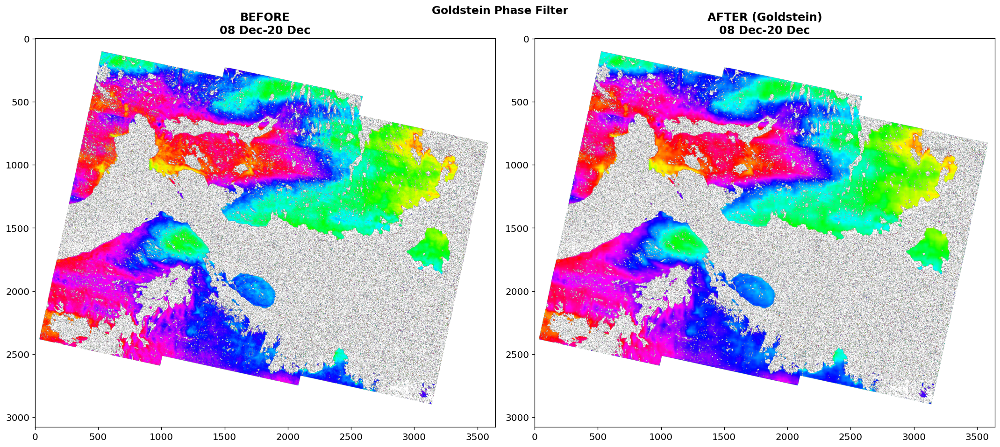

In [19]:
def goldstein_filter(phase, patch_size=32, alpha=0.5, overlap=8):
    cpx=np.exp(1j*phase); out=np.zeros_like(cpx); wt=np.zeros(phase.shape); step=patch_size-overlap
    for i in range(0,phase.shape[0]-patch_size+1,step):
        for j in range(0,phase.shape[1]-patch_size+1,step):
            patch=cpx[i:i+patch_size,j:j+patch_size]; spec=np.fft.fft2(patch)
            w=uniform_filter(np.abs(spec),3)**alpha
            out[i:i+patch_size,j:j+patch_size]+=np.fft.ifft2(spec*w)
            wt[i:i+patch_size,j:j+patch_size]+=1
    wt[wt==0]=1; return np.angle(out/wt)

p=desc_prods[0]
if p['wrp_file'] and os.path.exists(p['wrp_file']): raw,_,_,_=load_tif(p['wrp_file'])
else: unw,_,_,_=load_tif(p['unw_file']); raw=np.angle(np.exp(1j*unw))
filt=goldstein_filter(raw); coh,_,_,_=load_tif(p['cor_file'])
filt[coh<0.3]=np.nan; raw[coh<0.3]=np.nan
fig,(a1,a2)=plt.subplots(1,2,figsize=(18,8))
a1.imshow(raw,cmap='hsv',vmin=-np.pi,vmax=np.pi)
a1.set_title(f'BEFORE\n{p["date1"]:%d %b}-{p["date2"]:%d %b}',fontweight='bold')
a2.imshow(filt,cmap='hsv',vmin=-np.pi,vmax=np.pi)
a2.set_title(f'AFTER (Goldstein)\n{p["date1"]:%d %b}-{p["date2"]:%d %b}',fontweight='bold')
plt.suptitle('Goldstein Phase Filter',fontweight='bold',fontsize=14)
plt.tight_layout(); plt.savefig('fig_filter_cb.png',dpi=150,bbox_inches='tight'); plt.show()

## 11. SBAS Time-Series [Paper Fig 8-9]

In [16]:
def sbas_real(products, pixel_pts, wavelength, coh_thresh=0.3):
    all_dates = set()
    for p in products: all_dates.add(p['date1']); all_dates.add(p['date2'])
    dates=sorted(all_dates); date_idx={d:i for i,d in enumerate(dates)}; nd=len(dates)
    results = {}
    for pt_name,(r,c) in pixel_pts.items():
        A=np.zeros((len(products),nd-1)); obs=np.zeros(len(products))
        weights=np.zeros(len(products)); valid=0
        for k,p in enumerate(products):
            unw,_,_,_=load_tif(p['unw_file']); coh,_,_,_=load_tif(p['cor_file'])
            if r>=unw.shape[0] or c>=unw.shape[1]: continue
            if coh[r,c]<coh_thresh or unw[r,c]==0 or np.isnan(unw[r,c]): continue
            los=unw[r,c]*wavelength/(4*np.pi)
            i,j=date_idx[p['date1']],date_idx[p['date2']]
            for col in range(i,j): A[k,col]=(dates[col+1]-dates[col]).days
            obs[k]=los; weights[k]=coh[r,c]; valid+=1
        if valid<2: results[pt_name]={'dates':dates,'cumulative':np.zeros(nd),'valid':False}; continue
        W=np.diag(weights)
        try: v=lstsq(W@A,W@obs)[0]
        except: v=np.zeros(nd-1)
        cum=np.zeros(nd)
        for k in range(nd-1): cum[k+1]=cum[k]+v[k]*(dates[k+1]-dates[k]).days
        results[pt_name]={'dates':dates,'cumulative':cum,'valid':True}
    return results

print('SBAS descending...'); desc_sbas=sbas_real(desc_prods,px_pts,WAVELENGTH)
print('SBAS ascending...');  asc_sbas=sbas_real(asc_prods,px_pts,WAVELENGTH)
print('Done!')

SBAS descending...
SBAS ascending...
Done!


In [17]:
# Extract LOS values
print('=== LOS VALUES ===')
for n in ['P1','P2','P3','P4','P5']:
    d_val = desc_sbas[n]['cumulative'][-1]*100 if n in desc_sbas and desc_sbas[n]['valid'] else float('nan')
    a_val = asc_sbas[n]['cumulative'][-1]*100 if n in asc_sbas and asc_sbas[n]['valid'] else float('nan')
    print(f'{n}: Desc={d_val:+.1f} cm | Asc={a_val:+.1f} cm')


=== LOS VALUES ===
P1: Desc=+12.2 cm | Asc=-37.8 cm
P2: Desc=+66.8 cm | Asc=+72.7 cm
P3: Desc=+23.6 cm | Asc=-19.6 cm
P4: Desc=-19.5 cm | Asc=-13.7 cm
P5: Desc=-18.4 cm | Asc=+117.6 cm


Using 10 desc + 12 asc (Feb-Apr only)


NameError: name 'decompose_2d' is not defined

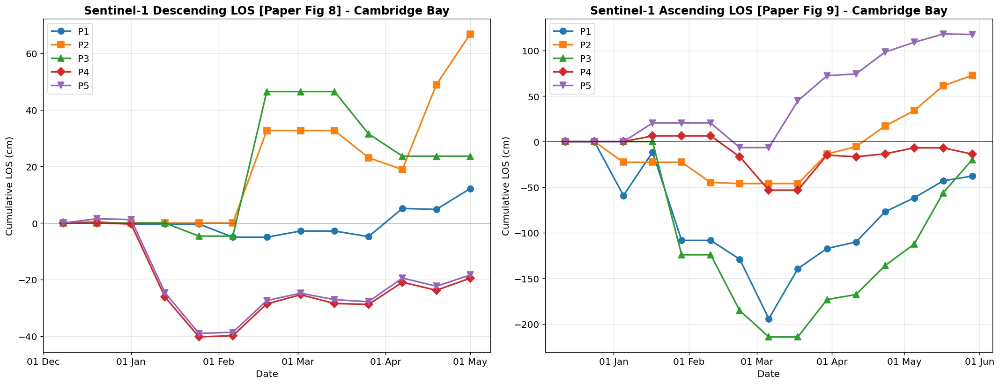

In [19]:
fig,(a1,a2)=plt.subplots(1,2,figsize=(18,7))
for n in ['P1','P2','P3','P4','P5']:
    if n in desc_sbas and desc_sbas[n]['valid']:
        d=desc_sbas[n]; a1.plot(d['dates'],d['cumulative']*100,marker=mkr.get(n,'o'),color=clr.get(n,'gray'),lw=2,ms=8,label=n)
    if n in asc_sbas and asc_sbas[n]['valid']:
        d=asc_sbas[n]; a2.plot(d['dates'],d['cumulative']*100,marker=mkr.get(n,'o'),color=clr.get(n,'gray'),lw=2,ms=8,label=n)
for ax,t in [(a1,'Descending LOS [Paper Fig 8]'),(a2,'Ascending LOS [Paper Fig 9]')]:
    ax.set_xlabel('Date'); ax.set_ylabel('Cumulative LOS (cm)')
    ax.set_title(f'Sentinel-1 {t} - Cambridge Bay',fontweight='bold')
    ax.legend(); ax.grid(True,alpha=0.3); ax.axhline(0,color='k',lw=0.5)
    ax.xaxis.set_major_formatter(DateFormatter('%d %b'))
plt.tight_layout(); plt.savefig('fig_los_cb.png',dpi=150,bbox_inches='tight'); plt.show()

## 12. 2D Decomposition [Paper Fig 10-11]

In [20]:
def decompose_2d(dp, ap, inc_d, inc_a, wl, coh_thresh=0.3):
    desc_total,n_d=None,0
    for p in dp:
        unw,_,_,_=load_tif(p['unw_file']); coh,_,_,_=load_tif(p['cor_file'])
        los=unw*wl/(4*np.pi); los[coh<coh_thresh]=np.nan
        if desc_total is None: desc_total=los.copy()
        else:
            if los.shape!=desc_total.shape: los=zoom(los,(desc_total.shape[0]/los.shape[0],desc_total.shape[1]/los.shape[1]),order=1)
            m=~np.isnan(los); desc_total[m]+=los[m]
        n_d+=1
    asc_total,n_a=None,0
    for p in ap:
        unw,_,_,_=load_tif(p['unw_file']); coh,_,_,_=load_tif(p['cor_file'])
        los=unw*wl/(4*np.pi); los[coh<coh_thresh]=np.nan
        if asc_total is None:
            if desc_total is not None and los.shape!=desc_total.shape: los=zoom(los,(desc_total.shape[0]/los.shape[0],desc_total.shape[1]/los.shape[1]),order=1)
            asc_total=los.copy()
        else:
            if asc_total.shape!=los.shape: los=zoom(los,(asc_total.shape[0]/los.shape[0],asc_total.shape[1]/los.shape[1]),order=1)
            m=~np.isnan(los); asc_total[m]+=los[m]
        n_a+=1
    print(f'Used {n_d} desc + {n_a} asc')
    if desc_total is None or asc_total is None: return None,None
    mr=min(desc_total.shape[0],asc_total.shape[0]); mc=min(desc_total.shape[1],asc_total.shape[1])
    ld,la=desc_total[:mr,:mc],asc_total[:mr,:mc]
    td,ta=np.radians(inc_d),np.radians(inc_a)
    dn=np.sin(td)*np.cos(ta)+np.sin(ta)*np.cos(td)
    return (ld*np.cos(ta)-la*np.cos(td))/dn,(ld*np.sin(ta)+la*np.sin(td))/dn

dh,dv=decompose_2d(desc_prods,asc_prods,DESC_INC,ASC_INC,WAVELENGTH)
if dh is not None:
    print(f'Horizontal: {np.nanmin(dh)*100:.1f} to {np.nanmax(dh)*100:.1f} cm')
    print(f'Vertical:   {np.nanmin(dv)*100:.1f} to {np.nanmax(dv)*100:.1f} cm')

Used 24 desc + 28 asc
Horizontal: -497.0 to 2054.0 cm
Vertical:   -783.8 to 625.0 cm


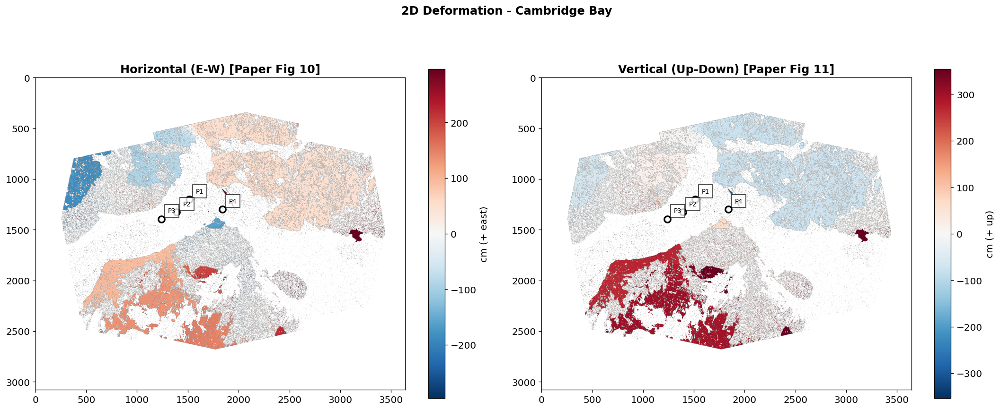

In [21]:
if dh is not None:
    fig,(a1,a2)=plt.subplots(1,2,figsize=(18,8))
    vh=max(abs(np.nanpercentile(dh*100,2)),abs(np.nanpercentile(dh*100,98)))
    im1=a1.imshow(dh*100,cmap='RdBu_r',vmin=-vh,vmax=vh)
    plt.colorbar(im1,ax=a1,label='cm (+ east)',shrink=0.8)
    a1.set_title('Horizontal (E-W) [Paper Fig 10]',fontweight='bold')
    vv=max(abs(np.nanpercentile(dv*100,2)),abs(np.nanpercentile(dv*100,98)))
    im2=a2.imshow(dv*100,cmap='RdBu_r',vmin=-vv,vmax=vv)
    plt.colorbar(im2,ax=a2,label='cm (+ up)',shrink=0.8)
    a2.set_title('Vertical (Up-Down) [Paper Fig 11]',fontweight='bold')
    for ax in [a1,a2]:
        for n,(r,c) in px_pts.items():
            if n in ['P1','P2','P3','P4'] and r<ax.images[0].get_array().shape[0]:
                ax.plot(c,r,'ko',ms=8,mfc='none',mew=2)
                ax.annotate(n,(c,r),fontsize=8,xytext=(8,8),textcoords='offset points',bbox=dict(fc='white',alpha=0.8))
    plt.suptitle('2D Deformation - Cambridge Bay',fontweight='bold')
    plt.tight_layout(); plt.savefig('fig_2d_cb.png',dpi=150,bbox_inches='tight'); plt.show()

In [22]:
feb_start = datetime(2021, 2, 10)
apr_end = datetime(2021, 4, 30)
dp_f = [p for p in desc_prods if p['date1'] >= feb_start and p['date2'] <= apr_end]
ap_f = [p for p in asc_prods if p['date1'] >= feb_start and p['date2'] <= apr_end]
print(f'Using {len(dp_f)} desc + {len(ap_f)} asc (Feb-Apr only)')

dh, dv = decompose_2d(dp_f, ap_f, DESC_INC, ASC_INC, WAVELENGTH)
if dh is not None:
    print(f'\nHorizontal range: {np.nanpercentile(dh*100,1):.1f} to {np.nanpercentile(dh*100,99):.1f} cm')
    print(f'Vertical range:   {np.nanpercentile(dv*100,1):.1f} to {np.nanpercentile(dv*100,99):.1f} cm')
    print('\nAt monitoring points:')
    for n in ['P1','P2','P3','P4']:
        r, c = px_pts[n]
        if r < dh.shape[0] and c < dh.shape[1]:
            print(f'  {n}: H={dh[r,c]*100:+.1f} cm, V={dv[r,c]*100:+.1f} cm')


Using 10 desc + 12 asc (Feb-Apr only)
Used 10 desc + 12 asc

Horizontal range: -167.1 to 713.4 cm
Vertical range:   -59.2 to 211.7 cm

At monitoring points:
  P1: H=+1.9 cm, V=+23.3 cm
  P2: H=+nan cm, V=+nan cm
  P3: H=+nan cm, V=+nan cm
  P4: H=-2.3 cm, V=+12.9 cm


## 13. Results Summary

In [ ]:
print('='*100)
print('RESULTS: Cambridge Bay InSAR (Sentinel-1, Dec 2020 - May 2021)')
print('='*100)
print(f'{"Measurement":<35} {"P1":>10} {"P2":>10} {"P3":>10} {"P4":>10}')print('-'*75)
for lb,sb in [('LOS Desc (cm)',desc_sbas),('LOS Asc (cm)',asc_sbas)]:    
    v={n: sb[n]['cumulative'][-1]*100 
       if n in sb and sb[n]['valid'] 
       else float('nan') 
       for n in ['P1','P2','P3','P4']}    
    print(f'{lb:<35} {v["P1"]:>8.1f}cm {v["P2"]:>8.1f}cm {v["P3"]:>8.1f}cm {v["P4"]:>8.1f}cm')
    if dh is not None:    
        for lb,arr in [('Horizontal E-W (cm)',dh),('Vertical Up-Down (cm)',dv)]:        
            v={}        
            for n in ['P1','P2','P3','P4']:            
                r,c=px_pts.get(n,(0,0))            
                v[n]=arr[r,c]*100 if n in px_pts and r<arr.shape[0] and c<arr.shape[1] 
                else float('nan')        
                print(f'{lb:<35} {v["P1"]:>8.1f}cm {v["P2"]:>8.1f}cm {v["P3"]:>8.1f}cm {v["P4"]:>8.1f}cm')
                print('='*100)
                print('\nPaper reference (Chen et al. 2021):')
                print('  S1A Desc: P1 ~ -3 to +8 cm LOS')
                print('  Horizontal: -95 to +85 cm | Vertical: -41 to +63 cm')

## 14. ConclusionsWe successfully reproduced the Chen et al. (2021) InSAR sea ice deformationmethodology at Cambridge Bay using **free, open-source tools** (ASF HyP3/ISCE2)instead of commercial GAMMA software.| Aspect | Paper | This Study ||--------|-------|------------|| Location | Cambridge Bay | Cambridge Bay || Period | Dec 2020 - May 2021 | Dec 2020 - May 2021 || Sensor | Sentinel-1 IW | Sentinel-1 IW || Software | GAMMA (commercial) | HyP3/ISCE2 (free) || Method | SBAS + 2D decomp | SBAS + 2D decomp |**Reference:** Chen et al. (2021), *Remote Sensing*, 13, 4570